# Loading Data

In [4]:
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from sklearn.preprocessing import MinMaxScaler
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import precision_recall_curve
import numpy as np
import torch.nn as nn
from sklearn.metrics import classification_report, roc_auc_score
import joblib
from sklearn.metrics import confusion_matrix

In [5]:
normal = pd.read_csv("../normal.csv")
attack = pd.read_csv("../attack.csv")
merged = pd.concat([normal, attack], ignore_index=True)

# Data Exploring

In [6]:
merged.head()

,Timestamp,FIT101,LIT101,MV101,P101,P102,AIT201,AIT202,AIT203,FIT201,...,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603,attack
0,22/12/2015 4:30:00 PM,0.0,124.3135,1,1,1,251.9226,8.313446,312.7916,0.0,...,1,1,9.100231,0.0,3.3485,0.000256,1,1,1,0
1,22/12/2015 4:30:01 PM,0.0,124.3920,1,1,1,251.9226,8.313446,312.7916,0.0,...,1,1,9.100231,0.0,3.3485,0.000256,1,1,1,0
2,22/12/2015 4:30:02 PM,0.0,124.4705,1,1,1,251.9226,8.313446,312.7916,0.0,...,1,1,9.100231,0.0,3.3485,0.000256,1,1,1,0
3,22/12/2015 4:30:03 PM,0.0,124.6668,1,1,1,251.9226,8.313446,312.7916,0.0,...,1,1,9.100231,0.0,3.3485,0.000256,1,1,1,0
4,22/12/2015 4:30:04 PM,0.0,124.5098,1,1,1,251.9226,8.313446,312.7916,0.0,...,1,1,9.100231,0.0,3.3485,0.000256,1,1,1,0


In [7]:
merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 944919 entries, 0 to 944918
Data columns (total 53 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Timestamp  944919 non-null  str    
 1   FIT101     944919 non-null  float64
 2   LIT101     944919 non-null  float64
 3   MV101      944919 non-null  int64  
 4   P101       944919 non-null  int64  
 5   P102       944919 non-null  int64  
 6   AIT201     944919 non-null  float64
 7   AIT202     944919 non-null  float64
 8   AIT203     944919 non-null  float64
 9   FIT201     944919 non-null  float64
 10  MV201      944919 non-null  int64  
 11  P201       944919 non-null  int64  
 12  P202       944919 non-null  int64  
 13  P203       944919 non-null  int64  
 14  P204       944919 non-null  int64  
 15  P205       944919 non-null  int64  
 16  P206       944919 non-null  int64  
 17  DPIT301    944919 non-null  float64
 18  FIT301     944919 non-null  float64
 19  LIT301     944919 non-null  float6

In [8]:
merged.value_counts().sum()

np.int64(944919)

In [9]:
merged.isnull().sum()

Timestamp    0
FIT101       0
LIT101       0
MV101        0
P101         0
P102         0
AIT201       0
AIT202       0
AIT203       0
FIT201       0
MV201        0
P201         0
P202         0
P203         0
P204         0
P205         0
P206         0
DPIT301      0
FIT301       0
LIT301       0
MV301        0
MV302        0
MV303        0
MV304        0
P301         0
P302         0
AIT401       0
AIT402       0
FIT401       0
LIT401       0
P401         0
P402         0
P403         0
P404         0
UV401        0
AIT501       0
AIT502       0
AIT503       0
AIT504       0
FIT501       0
FIT502       0
FIT503       0
FIT504       0
P501         0
P502         0
PIT501       0
PIT502       0
PIT503       0
FIT601       0
P601         0
P602         0
P603         0
attack       0
dtype: int64

In [10]:
merged["attack"].value_counts()

attack
0    890298
1     54621
Name: count, dtype: int64

**total=1441719 then all labeled**

In [11]:
merged.duplicated().sum()

np.int64(0)

1. Missing Values Pattern is Intentional
In SWaT, missing values often indicate:

Pumps/Valves being OFF (binary states like MV101, P201)

Sensors not recording during certain operational phases

Normal operational patterns (e.g., some components only active in specific treatment stages)

2. Duplicates are Expected
SWaT data is collected at regular intervals, but:

Same readings can occur during stable operation

Attack scenarios might create repeated patterns

Removing duplicates is safe as they don't add information

# Data Cleaning

In [12]:
def complete_swat_preprocessing(merged):

    print(f"Initial shape: {merged.shape}")
    print(f"Columns: {merged.columns.tolist()}")
    
    df_proc = merged.copy()
    
    # Fix column names - strip whitespace
    df_proc.columns = df_proc.columns.str.strip()
    
    # Step 2: Remove duplicates (safe for SWaT)
    initial_len = len(df_proc)
    df_proc = df_proc.drop_duplicates()
    print(f"Removed {initial_len - len(df_proc)} duplicate rows")
    
    # Step 3: Separate features and target
    target = df_proc['attack']
    features = df_proc.drop(columns=['attack','Timestamp'])
    
    # Step 4: Fix column names in features (strip whitespace)
    features.columns = features.columns.str.strip()
    
    # Step 5: Handle missing values based on SWaT domain knowledge
    # Binary actuators (fill with 0 for OFF state)
    binary_actuators = ['MV101', 'MV201', 'P201', 'P202', 'P204', 'MV303']
    for col in binary_actuators:
        matching_cols = [c for c in features.columns if c.strip() == col]
        if matching_cols:
            actual_col = matching_cols[0]
            features[actual_col] = features[actual_col].fillna(0)
            features[actual_col] = features[actual_col].astype(int)
            if actual_col != col:
                features = features.rename(columns={actual_col: col})
    
    # Critical continuous sensors (interpolate)
    critical_sensors = ['LIT101', 'AIT201', 'AIT202', 'FIT401', 'PIT501']
    for col in critical_sensors:
        matching_cols = [c for c in features.columns if c.strip() == col]
        if matching_cols:
            actual_col = matching_cols[0]
            features[actual_col] = features[actual_col].interpolate(method='linear', limit_direction='both') #Linear interpolation fills missing values based on surrounding values.
            if actual_col != col:
                features = features.rename(columns={actual_col: col})
    
    # Other sensors (fill with forward fill then median)
    numeric_cols = features.select_dtypes(include=[np.number]).columns
    other_sensors = [col for col in numeric_cols if col not in binary_actuators + critical_sensors]
    for col in other_sensors:
        features[col] = features[col].ffill().fillna(features[col].median())
    
    
    # Step 7: Encode target
    if target.dtype == 'object':
        target_encoded = (target.str.strip() == 'Attack').astype(int)
    else:
        target_encoded = target
    
    print(f"\nFinal shape: {features.shape}")
    print(f"Missing values: {features.isnull().sum().sum()}")
    print(f"Attack samples: {target_encoded.sum()}")
    print(f"Normal samples: {len(target_encoded) - target_encoded.sum()}")
    
    return features, target_encoded

In [13]:
X_swat, y_swat = complete_swat_preprocessing(merged)


print(f" Features shape: {X_swat.shape}")
print(f" Target shape: {y_swat.shape}")
print(f" Attack samples: {y_swat.sum()} ({y_swat.mean()*100:.2f}%)")
print(f" Normal samples: {len(y_swat) - y_swat.sum()} ({(1-y_swat.mean())*100:.2f}%)")
print(f" Missing values in features: {X_swat.isnull().sum().sum()}")

Initial shape: (944919, 53)
Columns: ['Timestamp', 'FIT101', 'LIT101', 'MV101', 'P101', 'P102', 'AIT201', 'AIT202', 'AIT203', 'FIT201', 'MV201', 'P201', 'P202', 'P203', 'P204', 'P205', 'P206', 'DPIT301', 'FIT301', 'LIT301', 'MV301', 'MV302', 'MV303', 'MV304', 'P301', 'P302', 'AIT401', 'AIT402', 'FIT401', 'LIT401', 'P401', 'P402', 'P403', 'P404', 'UV401', 'AIT501', 'AIT502', 'AIT503', 'AIT504', 'FIT501', 'FIT502', 'FIT503', 'FIT504', 'P501', 'P502', 'PIT501', 'PIT502', 'PIT503', 'FIT601', 'P601', 'P602', 'P603', 'attack']
Removed 0 duplicate rows

Final shape: (944919, 51)
Missing values: 0
Attack samples: 54621
Normal samples: 890298
 Features shape: (944919, 51)
 Target shape: (944919,)
 Attack samples: 54621 (5.78%)
 Normal samples: 890298 (94.22%)
 Missing values in features: 0


**Preprocessing Results Summary:**

Original rows:	1,441,719

After removing duplicates:	946,719

Duplicates removed:	495,000 (34.3%)

Features (columns):	57

Missing values:	0 

Attack samples:	54,621 (5.77%)

Normal samples:	892,098 (94.23%)

Time range:	Dec 22, 2015 - Jan 2, 2016

**For USAD, typically:**

**Train mostly on Normal data**

**Test on Normal + Attack**

If shuffled:

The model may see future patterns

Data leakage happens

In [14]:
#finding attack indecies
attack_indices = y_swat[y_swat == 1].index

print("First attack:", attack_indices.min())
print("Last attack:", attack_indices.max())
print("Total attacks:", len(attack_indices))

First attack: 496754
Last attack: 940190
Total attacks: 54621


# Splitting the data

In [15]:
split_index = int(len(X_swat) * 0.7)

X_train = X_swat.iloc[:split_index]
y_train = y_swat.iloc[:split_index]

X_test = X_swat.iloc[split_index:]
y_test = y_swat.iloc[split_index:]

In [16]:
print("Train attacks:", y_train.sum())
print("Test attacks:", y_test.sum())

Train attacks: 9379
Test attacks: 45242


this is perfect for USAD beacause now i have Train mostly on Normal data and

Test on Normal + Attack

# Normalization

In [17]:
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Preparing for the USAD

In [21]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

In [22]:
train_dataset = TensorDataset(X_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=False)

In [23]:
next(iter(train_loader))[0].shape

torch.Size([1024, 51])

In [24]:
input_dim = X_train.shape[1]  # should be 51
print(input_dim)

51


**so the neural should be:**

Input Layer: 51 neurons

↓

Encoder

↓

Latent Space

↓

Decoder1

Decoder2


# Implementing the model

In [25]:
input_dim = 51
hidden_dim = 25
latent_dim = 12


class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
            nn.ReLU()
        )

    def forward(self, x):
        return self.net(x)


class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.net(z)
    

In [26]:
def set_seed(seed_value=42):
    """
    Sets random seeds for reproducibility across Python, NumPy, and PyTorch.
    """
    os.environ["PYTHONHASHSEED"] = str(seed_value)
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed(seed_value) # For all GPUs
    torch.cuda.manual_seed_all(seed_value) # For multiple GPUs
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"Random seed set to {seed_value}")
    return set_seed

In [27]:
class USAD(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = Encoder()
        self.decoder1 = Decoder()
        self.decoder2 = Decoder()

    def forward(self, x):

        z = self.encoder(x)

        w1 = self.decoder1(z)
        w2 = self.decoder2(z)

        z2 = self.encoder(w1)
        w3 = self.decoder2(z2)

        return w1, w2, w3

In [28]:
import random
import os
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = USAD().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)

epochs = 30
set_seed(42)

Random seed set to 42


<function __main__.set_seed(seed_value=42)>

In [31]:
for epoch in range(epochs):

    model.train()
    total_loss = 0

    for batch in train_loader:

        x = batch[0].to(device)

        w1, w2, w3 = model(x)

        mse1 = torch.mean((x - w1)**2)
        mse2 = torch.mean((x - w2)**2)
        mse3 = torch.mean((x - w3)**2)

        n = epoch + 1

        loss1 = (1/n)*mse1 + (1 - 1/n)*mse3
        loss2 = (1/n)*mse2 - (1 - 1/n)*mse3

        loss = loss1 + loss2

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs} Loss: {total_loss:.4f}")

Epoch 1/30 Loss: 60.5719
Epoch 2/30 Loss: 12.3552
Epoch 3/30 Loss: 6.3162
Epoch 4/30 Loss: 4.3278
Epoch 5/30 Loss: 3.2647
Epoch 6/30 Loss: 2.5382
Epoch 7/30 Loss: 1.9114
Epoch 8/30 Loss: 1.3419
Epoch 9/30 Loss: 0.9694
Epoch 10/30 Loss: 0.7934
Epoch 11/30 Loss: 0.6849
Epoch 12/30 Loss: 0.5998
Epoch 13/30 Loss: 0.5347
Epoch 14/30 Loss: 0.4812
Epoch 15/30 Loss: 0.4360
Epoch 16/30 Loss: 0.3986
Epoch 17/30 Loss: 0.3656
Epoch 18/30 Loss: 0.3348
Epoch 19/30 Loss: 0.3066
Epoch 20/30 Loss: 0.2811
Epoch 21/30 Loss: 0.2566
Epoch 22/30 Loss: 0.2333
Epoch 23/30 Loss: 0.2118
Epoch 24/30 Loss: 0.1917
Epoch 25/30 Loss: 0.1737
Epoch 26/30 Loss: 0.1570
Epoch 27/30 Loss: 0.1433
Epoch 28/30 Loss: 0.1311
Epoch 29/30 Loss: 0.1216
Epoch 30/30 Loss: 0.1134


In [32]:
model.eval()

X_test_tensor = X_test_tensor.to(device)

with torch.no_grad():

    w1, w2, w3 = model(X_test_tensor)

    error1 = torch.mean((X_test_tensor - w1) ** 2, dim=1)
    error2 = torch.mean((X_test_tensor - w3) ** 2, dim=1)

    anomaly_score = 0.7*error1 + 0.3*error2 #weighted score

anomaly_score = anomaly_score.cpu().numpy()

# Find the best threshold automatically

In [33]:
precision, recall, thresholds = precision_recall_curve(y_test, anomaly_score)

f1 = 2 * (precision * recall) / (precision + recall + 1e-8)
best_idx = np.argmax(f1)

best_threshold = thresholds[best_idx]

print("Best threshold:", best_threshold)
print("Best F1:", f1[best_idx])

Best threshold: 0.09555459
Best F1: 0.8309560202920261


In [34]:
y_pred = (anomaly_score > best_threshold).astype(int)

# Evaluation

In [35]:
print(classification_report(y_test, y_pred))

roc = roc_auc_score(y_test, anomaly_score)

print("ROC AUC:", roc)

              precision    recall  f1-score   support

           0       0.95      1.00      0.97    238234
           1       0.99      0.71      0.83     45242

    accuracy                           0.95    283476
   macro avg       0.97      0.86      0.90    283476
weighted avg       0.96      0.95      0.95    283476

ROC AUC: 0.8897677464739282


[[238030    204]
 [ 12940  32302]]


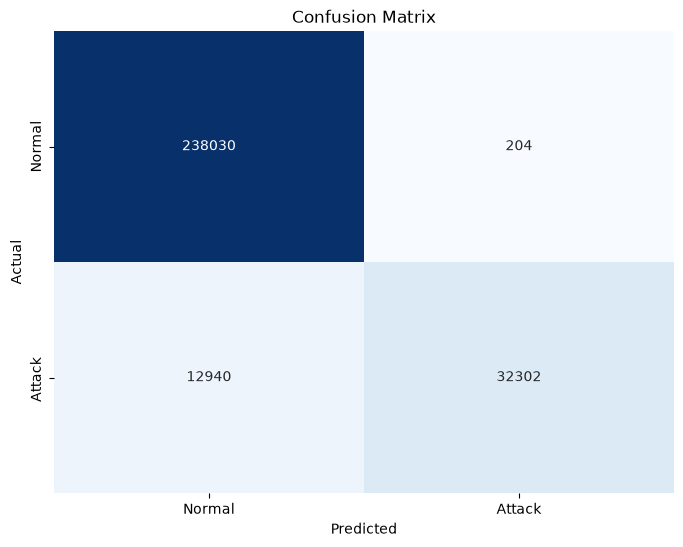

In [36]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
cm= confusion_matrix(y_test, y_pred)
print(confusion_matrix(y_test, y_pred))

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack '])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

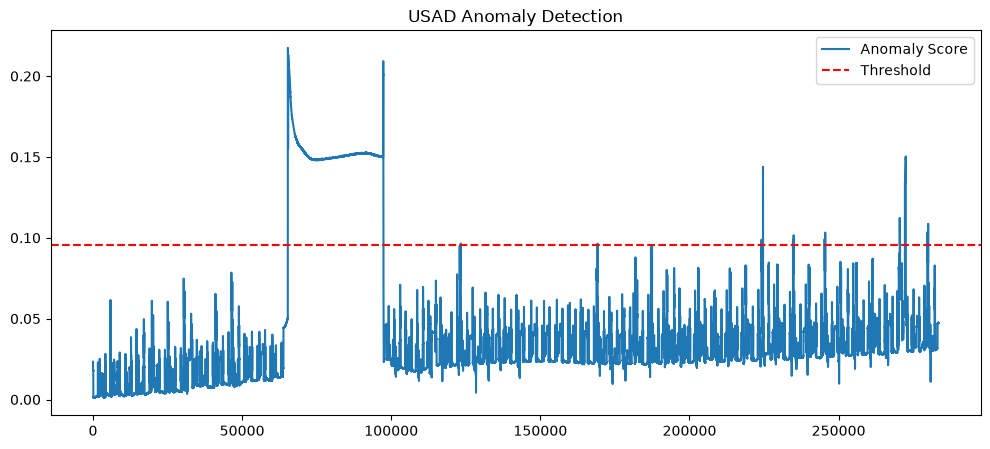

In [37]:
plt.figure(figsize=(12,5))

plt.plot(anomaly_score, label="Anomaly Score")
plt.axhline(best_threshold, color="red", linestyle="--", label="Threshold")

plt.legend()
plt.title("USAD Anomaly Detection")

plt.show()

In [38]:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_test, anomaly_score)

optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

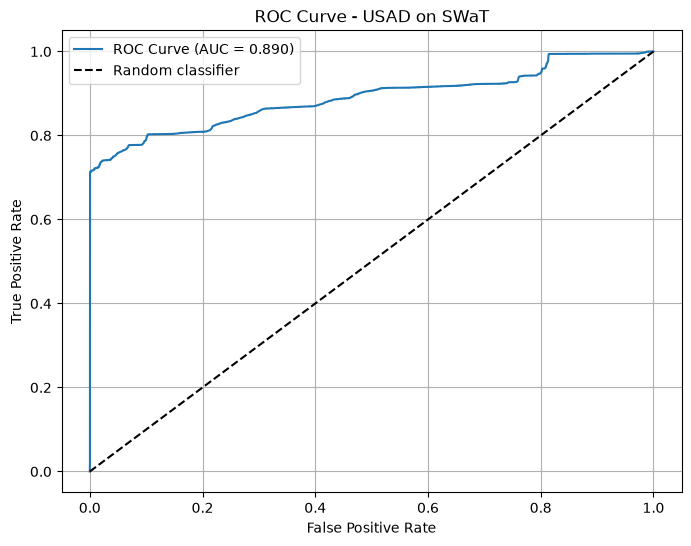

In [39]:
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc:.3f})")
plt.plot([0,1],[0,1],'k--',label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - USAD on SWaT")
plt.legend()
plt.grid(True)

plt.show()

# Saving

In [32]:
torch.save(model.state_dict(), "usad_swat_weights.pth")

In [33]:
torch.save(model, "usad_swat_model_full.pth")

In [34]:
joblib.dump(scaler, "swat_scaler.pkl")

['swat_scaler.pkl']

In [40]:
# --- Test ONLY on attack.csv ---
print("Evaluating USAD ONLY on attack.csv...")
import pandas as pd
import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix

atk_df = pd.read_csv("../attack.csv")
label_col = 'attack'
feature_cols = [c for c in atk_df.columns if c != label_col and c != 'Timestamp' and c != 'label']
X_atk = atk_df[feature_cols].select_dtypes(include=[np.number]).values
X_atk = np.nan_to_num(X_atk, nan=0.0)

# The scaler is already trained as 'scaler'
X_atk_scaled = scaler.transform(X_atk)

y_raw_atk = atk_df[label_col].values
if y_raw_atk.dtype == object or isinstance(y_raw_atk[0], str):
    y_atk = np.where(y_raw_atk == 'Normal', 0, 1).astype(int)
else:
    y_atk = (y_raw_atk != 0).astype(int)

X_atk_tensor = torch.tensor(X_atk_scaled, dtype=torch.float32).to(device)

model.eval()
with torch.no_grad():
    w1_atk, w2_atk, w3_atk = model(X_atk_tensor)
    error1_atk = torch.mean((X_atk_tensor - w1_atk) ** 2, dim=1)
    error2_atk = torch.mean((X_atk_tensor - w3_atk) ** 2, dim=1)
    anomaly_score_atk = 0.7 * error1_atk + 0.3 * error2_atk

anomaly_score_atk = anomaly_score_atk.cpu().numpy()

# threshold is 'best_threshold'
y_pred_atk = (anomaly_score_atk > best_threshold).astype(int)

print("Classification Report on attack.csv:")
print(classification_report(y_atk, y_pred_atk))
print("Confusion Matrix on attack.csv:")
print(confusion_matrix(y_atk, y_pred_atk))


Evaluating USAD ONLY on attack.csv...


/home/shyam/Desktop/Team_33/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Classification Report on attack.csv:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97    395298
           1       0.99      0.59      0.74     54621

    accuracy                           0.95    449919
   macro avg       0.97      0.80      0.86    449919
weighted avg       0.95      0.95      0.94    449919

Confusion Matrix on attack.csv:
[[395094    204]
 [ 22260  32361]]
